# Rosetta decision layer: analysis notebook

Reads `results/rosetta_bench.sqlite`, which `bench results db` rebuilds from the run folders in `results/runs/`
(the folders are the evidence; the database is derived). Re-run all cells after `bench results db` to refresh.

**What is compared**
- **Representation** of the generator's instructions: **P** plain prose prompt, **H** Rosetta human view (`.md`),
  **M** Rosetta machine view (`.cpn` packet).
- **Decision layer** before generation: **none**, **jevmodel** (Jev via jevmodel.org), **clef-ollama** (clef via Ollama),
  **consensus** (both must agree).
- **Outcome**: hidden acceptance tests in a Docker sandbox for code tasks; *no code produced* for no-code requests.

**Read the caveats before the numbers**: small task sets, author-written labels for the routing smoke corpus,
placeholder (uncalibrated) thresholds, one temperature-0 sample per prompt. Smoke runs establish wiring, not performance.

In [1]:
import json, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DB = Path("..") / "results" / "rosetta_bench.sqlite"
con = sqlite3.connect(DB)
q = lambda sql, *args: pd.read_sql_query(sql, con, params=args)

# Chart palette: first three categorical slots (validated all-pairs, light mode) and chart ink.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "legend.frameon": False,
})
pd.set_option("display.width", 200)
print(f"database: {DB.resolve()}")

database: G:\dev2\rosetta-bench\.worktrees\exp-decision-layer\results\rosetta_bench.sqlite


## 1. Runs and metadata

Every run, from the database's `runs` table, with the note from the experiment log.

In [2]:
runs = q("SELECT path, kind, run_id, created_at, synthetic, live FROM runs ORDER BY path")
log = pd.read_json(Path("..") / "results" / "runs.jsonl", lines=True)[["path", "note"]]
runs.merge(log, on="path", how="left")

,path,kind,run_id,created_at,synthetic,live,note
0,runs/2026-11-09_01_experiment-smoke-fake,experiment,run-0609dfc6a525,2026-11-08T22:21:46.482384+00:00,1,0,Phase 1 offline wiring check of the experiment...
1,runs/2026-11-09_02_decision-smoke-fake,decision,dec-77042fd7b6c3,2026-11-08T22:42:12.000718+00:00,1,0,Phase 3 offline wiring check of the shadow dec...
2,runs/2026-11-09_03_probe-jevmodel,probe,2026-11-09_03_probe-jevmodel,2026-11-08T22:45:18+00:00,0,1,First live jevmodel.org call; reply reported j...
3,runs/2026-11-09_04_decision-smoke-jevmodel-qs1.0,decision,dec-da2d233dfa8b,2026-11-08T22:47:38.669566+00:00,0,1,"Live Jev shadow run, question set 1.0, placeho..."
4,runs/2026-11-09_05_probe-clef-http400,probe,2026-11-09_05_probe-clef-http400,2026-11-08T22:49:08+00:00,0,1,clef via Ollama rejected noul criteria keyed y...
5,runs/2026-11-09_06_probe-clef,probe,2026-11-09_06_probe-clef,2026-11-08T22:50:13+00:00,0,1,clef probe with portable question set 1.1; ser...
6,runs/2026-11-09_07_decision-smoke-jevmodel-qs1.1,decision,dec-2d2e1f1d2b13,2026-11-08T22:54:56.732495+00:00,0,1,Live Jev shadow run on question set 1.1 for a ...
7,runs/2026-11-09_08_decision-smoke-clef-qs1.1,decision,dec-f2665c016492,2026-11-08T22:55:42.714534+00:00,0,1,Live clef shadow run on question set 1.1.
8,runs/2026-11-09_09_usefulness-matrix-live,usefulness,use-ed79aa225cee,2026-11-08T23:33:15+00:00,0,1,Live 12-arm matrix (P/H/M x none/jev/clef/cons...


## 2. Representation × decision matrix

The latest **live** usefulness run. Each arm is charged the tokens and time of the generation, decision and sandbox calls it used.

In [3]:
run = q("SELECT path FROM runs WHERE kind='usefulness' AND live=1 ORDER BY created_at DESC LIMIT 1").path[0]
trials = q("SELECT * FROM usefulness_trials WHERE run_path=?", run)
trials["tokens"] = trials.generator_tokens_in + trials.generator_tokens_out + trials.decision_tokens
REPS, DECIDERS = ["P", "H", "M"], ["none", "jevmodel", "clef-ollama", "consensus"]

def arm_table(t):
    g = t.groupby(["rep", "decider"])
    out = pd.DataFrame({
        "trials": g.size(),
        "verified successes": g.success.sum(),
        "accuracy": g.success.mean(),
        "generator tokens": g.apply(lambda x: (x.generator_tokens_in + x.generator_tokens_out).sum()),
        "decision tokens": g.decision_tokens.sum(),
        "p50 ms": g.total_ms.median(),
        "p95 ms": g.total_ms.quantile(0.95, interpolation="higher"),
    })
    out["tokens per verified success"] = (out["generator tokens"] + out["decision tokens"]) / out["verified successes"]
    return out

arms = arm_table(trials)
print(f"run: {run}  ·  trials: {len(trials)}  ·  every arm at 100%: {bool((arms.accuracy == 1).all())}")
arms.round(1)

run: runs/2026-11-09_09_usefulness-matrix-live  ·  trials: 216  ·  every arm at 100%: True


trials  verified successes  accuracy  generator tokens  decision tokens  p50 ms   p95 ms  tokens per verified success
rep decider                                                                                                                           
H   clef-ollama      18                  18       1.0             11482            12725  5277.1  22941.8                       1344.8
    consensus        18                  18       1.0             11482            28653  6646.2  24362.6                       2229.7
    jevmodel         18                  18       1.0             11482            15928  5569.9  23087.1                       1522.8
    none             18                  18       1.0             14063                0  4620.1  21666.2                        781.3
M   clef-ollama      18                  18       1.0             10705            19768  6174.7  29536.2                       1692.9
    consensus        18                  18       1.0             10705            28653  6736.8  30384.1                       2186.6
    jevmodel         18                  18       1.0             10705            25343  7231.0  31234.6                       2002.7
    none             18                  18       1.0             12304                0  4572.1  28122.4                        683.6
P   clef-ollama      18                  18       1.0             21190            12725  6433.0  46690.9                       1884.2
    consensus        18                  18       1.0             21190            28653  8035.4  48393.3                       2769.1
    jevmodel         18                  18       1.0             21190            15928  6809.9  47834.1                       2062.1
    none             18                  18       1.0             22232                0  5442.4  46131.6                       1235.1

In [4]:
pd.concat({
    "accuracy": arms.accuracy.unstack()[DECIDERS].reindex(REPS),
    "tokens per verified success": arms["tokens per verified success"].unstack()[DECIDERS].reindex(REPS).round(0),
    "p50 ms": arms["p50 ms"].unstack()[DECIDERS].reindex(REPS).round(0),
}, axis=1)

accuracy                                tokens per verified success                                 p50 ms                               
decider     none jevmodel clef-ollama consensus                        none jevmodel clef-ollama consensus    none jevmodel clef-ollama consensus
rep                                                                                                                                              
P            1.0      1.0         1.0       1.0                      1235.0   2062.0      1884.0    2769.0  5442.0   6810.0      6433.0    8035.0
H            1.0      1.0         1.0       1.0                       781.0   1523.0      1345.0    2230.0  4620.0   5570.0      5277.0    6646.0
M            1.0      1.0         1.0       1.0                       684.0   2003.0      1693.0    2187.0  4572.0   7231.0      6175.0    6737.0

### Tokens per verified success

Generator plus decision tokens divided by verified successes. Lower is cheaper. Values are labelled on the bars; the table above has the same figures.

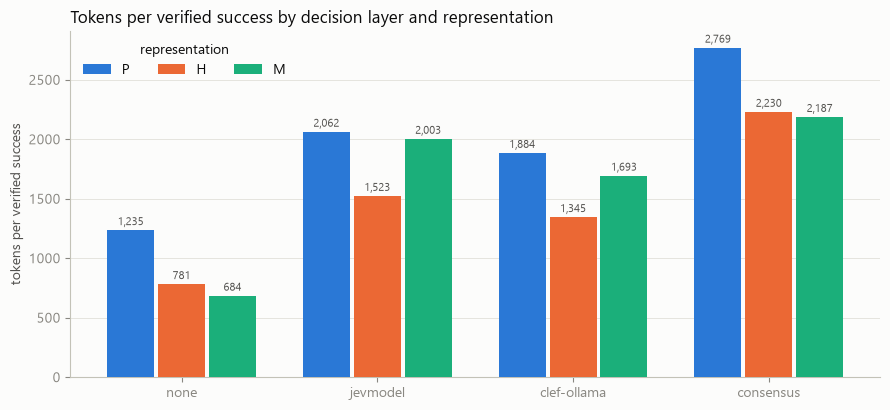

In [5]:
tps = arms["tokens per verified success"].unstack()[DECIDERS].reindex(REPS)
fig, ax = plt.subplots(figsize=(9, 4.2))
width, gap = 0.24, 0.02
for i, rep in enumerate(REPS):
    xs = [d + (i - 1) * (width + gap) for d in range(len(DECIDERS))]
    bars = ax.bar(xs, tps.loc[rep], width=width, color=SERIES[i], label=rep, zorder=3)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in tps.loc[rep]], padding=2, fontsize=8, color=INK2)
ax.set_xticks(range(len(DECIDERS)), DECIDERS)
ax.set_ylabel("tokens per verified success")
ax.set_title("Tokens per verified success by decision layer and representation", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(title="representation", ncols=3, loc="upper left")
plt.tight_layout(); plt.show()

### Where the time goes

Mean attributed milliseconds per stage, per arm, over **all** 18 trials: a stage a trial skipped (for example generation after a decline) counts as 0 ms, so every arm is averaged over the same trials. Decision time is the provider calls before generation; sandbox time is running the hidden tests.

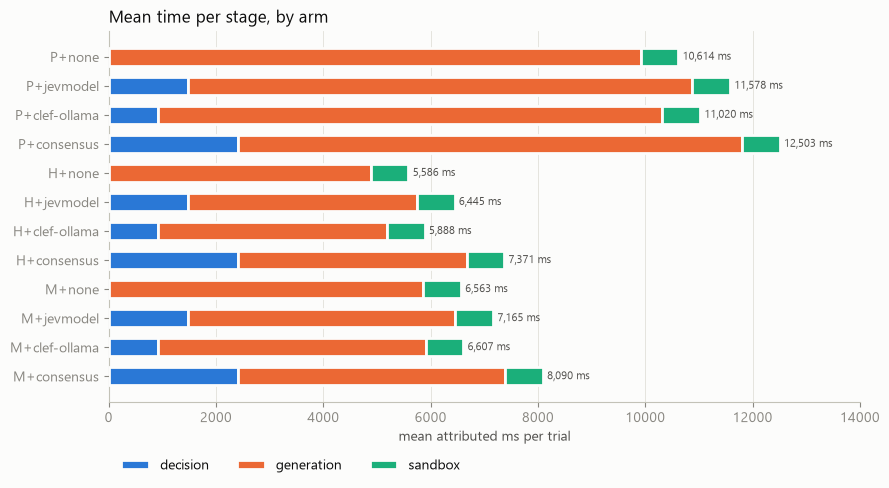

In [6]:
stage_cols = ["decision_ms", "generation_ms", "sandbox_ms"]
stages = trials.assign(**{c: trials[c].fillna(0) for c in stage_cols}).groupby("arm")[stage_cols].mean()
order = [f"{r}+{d}" for r in REPS for d in DECIDERS]
stages = stages.reindex(order)
fig, ax = plt.subplots(figsize=(9, 5))
left = [0.0] * len(stages)
for i, (col, label) in enumerate([("decision_ms", "decision"), ("generation_ms", "generation"), ("sandbox_ms", "sandbox")]):
    ax.barh(stages.index, stages[col], left=left, color=SERIES[i], label=label, height=0.62, edgecolor=SURFACE, linewidth=2, zorder=3)
    left = [l + v for l, v in zip(left, stages[col])]
for y, total in enumerate(left):
    ax.text(total + 80, y, f"{total:,.0f} ms", va="center", fontsize=8, color=INK2)
ax.invert_yaxis()
ax.set_xlabel("mean attributed ms per trial")
ax.set_title("Mean time per stage, by arm", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(left) * 1.12)
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout(); plt.show()

## 3. Paired contrasts

Paired by task. *A better* / *B better* count tasks that one arm passed and the other failed. Ratios compare A with B (negative = A lower). Intervals are not estimated: 18 tasks is too few.

In [7]:
def contrast(a, b):
    ta, tb = trials[trials.arm == a].set_index("task_id"), trials[trials.arm == b].set_index("task_id")
    shared = ta.index.intersection(tb.index)
    ma, mb = arms.loc[tuple(a.split("+"))], arms.loc[tuple(b.split("+"))]
    return {"A": a, "B": b, "tasks": len(shared),
            "A better": int((ta.loc[shared].success & ~tb.loc[shared].success.astype(bool)).sum()),
            "B better": int((tb.loc[shared].success & ~ta.loc[shared].success.astype(bool)).sum()),
            "accuracy A−B (pp)": round(100 * (ma.accuracy - mb.accuracy), 1),
            "tokens/success A vs B": f"{ma['tokens per verified success'] / mb['tokens per verified success'] - 1:+.0%}",
            "p50 A vs B": f"{ma['p50 ms'] / mb['p50 ms'] - 1:+.0%}"}

representation = pd.DataFrame([contrast(f"{a}+{d}", f"{b}+{d}") for d in DECIDERS for a, b in (("P", "H"), ("P", "M"), ("H", "M"))])
decision_pairs = [("none", "jevmodel"), ("none", "clef-ollama"), ("none", "consensus"), ("jevmodel", "clef-ollama")]
decision = pd.DataFrame([contrast(f"{r}+{a}", f"{r}+{b}") for r in REPS for a, b in decision_pairs])
print("Representation: plain prompt vs Rosetta, within each decision mode"); display(representation)
print("Decision layer: without vs with, and Jev vs clef, within each representation"); display(decision)

Representation: plain prompt vs Rosetta, within each decision mode


,A,B,tasks,A better,B better,accuracy A−B (pp),tokens/success A vs B,p50 A vs B
0,P+none,H+none,18,0,0,0.0,+58%,+18%
1,P+none,M+none,18,0,0,0.0,+81%,+19%
2,H+none,M+none,18,0,0,0.0,+14%,+1%
3,P+jevmodel,H+jevmodel,18,0,0,0.0,+35%,+22%
4,P+jevmodel,M+jevmodel,18,0,0,0.0,+3%,-6%
5,H+jevmodel,M+jevmodel,18,0,0,0.0,-24%,-23%
6,P+clef-ollama,H+clef-ollama,18,0,0,0.0,+40%,+22%
7,P+clef-ollama,M+clef-ollama,18,0,0,0.0,+11%,+4%
8,H+clef-ollama,M+clef-ollama,18,0,0,0.0,-21%,-15%
9,P+consensus,H+consensus,18,0,0,0.0,+24%,+21%


Decision layer: without vs with, and Jev vs clef, within each representation


,A,B,tasks,A better,B better,accuracy A−B (pp),tokens/success A vs B,p50 A vs B
0,P+none,P+jevmodel,18,0,0,0.0,-40%,-20%
1,P+none,P+clef-ollama,18,0,0,0.0,-34%,-15%
2,P+none,P+consensus,18,0,0,0.0,-55%,-32%
3,P+jevmodel,P+clef-ollama,18,0,0,0.0,+9%,+6%
4,H+none,H+jevmodel,18,0,0,0.0,-49%,-17%
5,H+none,H+clef-ollama,18,0,0,0.0,-42%,-12%
6,H+none,H+consensus,18,0,0,0.0,-65%,-30%
7,H+jevmodel,H+clef-ollama,18,0,0,0.0,+13%,+6%
8,M+none,M+jevmodel,18,0,0,0.0,-66%,-37%
9,M+none,M+clef-ollama,18,0,0,0.0,-60%,-26%


## 4. Decision providers

### On the usefulness tasks

In [8]:
ud = q("SELECT * FROM usefulness_decisions WHERE run_path=?", run)
ud.groupby("provider").apply(lambda g: pd.Series({
    "tasks": len(g), "ACCEPT": (g.outcome == "ACCEPT").sum(), "NO_FIT": (g.outcome == "NO_FIT").sum(),
    "code → code_change": f"{((g.kind == 'code') & (g.route == 'code_change')).sum()}/{(g.kind == 'code').sum()}",
    "no-code → NO_FIT": f"{((g.kind == 'no_code') & (g.outcome == 'NO_FIT')).sum()}/{(g.kind == 'no_code').sum()}",
    "input tokens": g.input_tokens.sum(), "p50 ms": round(g.decision_ms.median()),
}), include_groups=False)

,tasks,ACCEPT,NO_FIT,code → code_change,no-code → NO_FIT,input tokens,p50 ms
provider,,,,,,,
clef-ollama,18,12,6,12/12,6/6,12725,846
jevmodel,18,12,6,12/12,6/6,15928,1433


### On the routing smoke corpus (32 cases, author labels, placeholder thresholds)

In [9]:
dc = q("SELECT d.*, r.path FROM decision_cases d JOIN runs r ON r.path = d.run_path WHERE r.live = 1")
def quality(g):
    fits = g[g.label_fits == 1]
    eligible = fits[fits.selected.notna()]
    called = g[g.p_fit.notna()]
    return pd.Series({
        "cases": len(g), "top-1 route": f"{(eligible.selected == eligible.label_route).sum()}/{len(eligible)}",
        "Brier (route_fits)": round(((called.p_fit - called.label_fits) ** 2).mean(), 4),
        "false accepts": int(((g.label_fits == 0) & (g.outcome == "ACCEPT")).sum()),
        "abstain": int((g.outcome == "ABSTAIN").sum()), "input tokens": int(g.input_tokens.sum()),
        "p50 ms": round(called.decision_ms.median()),
    })
dc.groupby(["provider", "question_set", "run_path"]).apply(quality, include_groups=False)

cases top-1 route  Brier (route_fits)  false accepts  abstain  input tokens  p50 ms
provider    question_set run_path                                                                                                                             
clef-ollama 1.1          runs/2026-11-09_08_decision-smoke-clef-qs1.1         32       19/20              0.0246              0        4         20788     875
jevmodel    1.0          runs/2026-11-09_04_decision-smoke-jevmodel-qs1.0     32       20/20              0.0388              1        2         25248    1397
            1.1          runs/2026-11-09_07_decision-smoke-jevmodel-qs1.1     32       20/20              0.0321              0        4         26178    1377

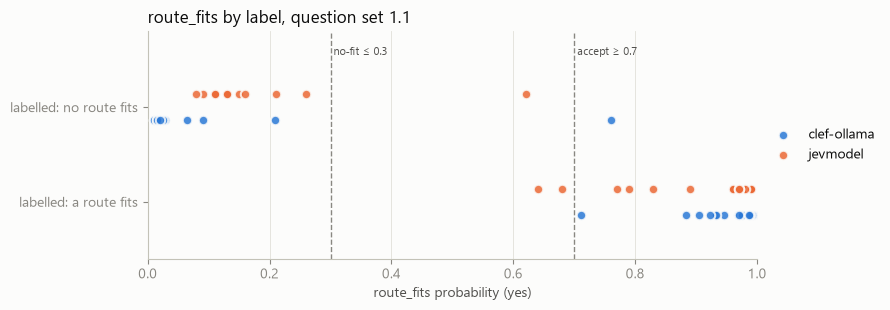

In [10]:
latest = dc[dc.question_set == dc.question_set.max()]
fig, ax = plt.subplots(figsize=(9, 3.2))
groups = [(1, "labelled: a route fits"), (0, "labelled: no route fits")]
for i, provider in enumerate(sorted(latest.provider.unique())):
    for j, (label, name) in enumerate(groups):
        p = latest[(latest.provider == provider) & (latest.label_fits == label)].p_fit.dropna()
        y = j + (i - 0.5) * 0.28
        ax.scatter(p, [y] * len(p), s=46, color=SERIES[i], alpha=0.85, edgecolors=SURFACE, linewidths=1.5, zorder=3,
                   label=provider if j == 0 else None)
ax.axvline(0.7, color=MUTED, linewidth=1, linestyle="--"); ax.axvline(0.3, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.7, 1.55, " accept ≥ 0.7", color=INK2, fontsize=8); ax.text(0.3, 1.55, " no-fit ≤ 0.3", color=INK2, fontsize=8)
ax.set_yticks([0, 1], [name for _, name in groups]); ax.set_ylim(-0.6, 1.8); ax.set_xlim(0, 1)
ax.set_xlabel("route_fits probability (yes)")
ax.set_title(f"route_fits by label, question set {latest.question_set.max()}", loc="left")
ax.grid(axis="y", visible=False); ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

## 5. Probes and receipts

In [11]:
display(q("SELECT run_path, provider, requested_model, served_model, http_status, input_tokens, tokens_remaining, round(elapsed_ms) AS ms, error_json FROM probes ORDER BY run_path"))
q("SELECT mode, provider, cost_basis, COUNT(*) AS receipts, SUM(verified_success) AS verified FROM receipts GROUP BY mode, provider, cost_basis ORDER BY mode, provider")

,run_path,provider,requested_model,served_model,http_status,input_tokens,tokens_remaining,ms,error_json
0,runs/2026-11-09_03_probe-jevmodel,jevmodel,jev-latest,jev-1.14.0,200,815.0,99185,1719.0,null
1,runs/2026-11-09_05_probe-clef-http400,clef-ollama,clef:cloud,NaN,400,NaN,NaN,1070.0,"{""kind"": ""INVALID_REQUEST"", ""detail"": ""call 1/..."
2,runs/2026-11-09_06_probe-clef,clef-ollama,clef:cloud,clef,200,673.0,NaN,1293.0,null


,mode,provider,cost_basis,receipts,verified
0,enforced,clef-ollama,subscription,54,54.0
1,enforced,consensus:jevmodel+clef-ollama,unknown,54,54.0
2,enforced,jevmodel,priced,54,54.0
3,shadow,clef-ollama,subscription,32,NaN
4,shadow,fake,free_local,32,NaN
5,shadow,jevmodel,priced,64,NaN


## 6. Reading these results

- **Ceiling.** On these 18 tasks every arm verified 18/18, so accuracy cannot separate the arms; the tasks are too easy for
  `kimi-k2.7-code:cloud`, and the baseline contract already makes the generator decline no-code requests.
- **Cost of a decision layer.** With nothing to gain in accuracy, the decision calls only add tokens and time here. A decision
  layer can pay off only where it avoids expensive work or catches failures the baseline misses — which needs harder tasks,
  costlier generation, or no-code requests the generator would otherwise act on.
- **Representation.** The Rosetta packet (M) used the fewest tokens per verified success in this run, but this is one
  temperature-0 sample per prompt; treat it as a lead to replicate, not a finding.
- **Next evidence needed.** Independent gold labels for `routing_v1`, thresholds calibrated on its calibration split and
  frozen, then held-out runs; and a harder usefulness corpus where the arms can actually differ.